In [1]:
# E1: environment and code (works on Kaggle and locally)
import sys
import subprocess
from pathlib import Path

REPO_USER = "agontuk19"
REPO_NAME = "mars-rover-segmentation"
IS_KAGGLE = Path("/kaggle").exists()

if IS_KAGGLE:
    ROOT = Path(f"/kaggle/working/{REPO_NAME}")
    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret("GITHUB_TOKEN")
        url = f"https://{token}@github.com/{REPO_USER}/{REPO_NAME}.git"
    except Exception:
        token = None
        url = f"https://github.com/{REPO_USER}/{REPO_NAME}.git"

    cmd = ["git", "-C", str(ROOT), "pull"] if ROOT.exists() else ["git", "clone", url, str(ROOT)]
    result = subprocess.run(cmd, capture_output=True, text=True)
    if result.returncode != 0:
        msg = result.stderr.replace(token, "***") if token else result.stderr
        raise RuntimeError(f"git failed. Is Internet On? Repo name/token correct?\n{msg}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "datasets", "segmentation-models-pytorch"], check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

assert (ROOT / "src").exists(), f"src/ not found under {ROOT}"
sys.path.append(str(ROOT))
print("Environment:", "Kaggle" if IS_KAGGLE else "local", "| ROOT:", ROOT)

Environment: Kaggle | ROOT: /kaggle/working/mars-rover-segmentation


In [2]:
# E2: configuration and test data
from src.utils.common import seed_everything, get_device
from src.data.dataset import load_raw_datasets, build_test_loaders

SEED, IMG_SIZE = 42, 512
BATCH_SIZE = 8 if IS_KAGGLE else 2
NUM_WORKERS = 2 if IS_KAGGLE else 0

OUT_DIR = Path("/kaggle/working/outputs/evaluation") if IS_KAGGLE else ROOT / "results" / "ensemble"
OUT_DIR.mkdir(parents=True, exist_ok=True)

seed_everything(SEED)
device = get_device()
use_amp = device.type == "cuda"

raw_datasets = load_raw_datasets()
test_loaders = build_test_loaders(raw_datasets, IMG_SIZE, BATCH_SIZE, NUM_WORKERS, pin_memory=use_amp)
print("Device:", device, "|", {s: len(l.dataset) for s, l in test_loaders.items()})

README.md:   0%|          | 0.00/3.14k [00:00<?, ?B/s]

data/train-00000-of-00013.parquet: reconstructing file:   0%|          |  0.00B /  475MB            

data/train-00000-of-00013.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00013.parquet: reconstructing file:   0%|          |  0.00B /  476MB            

data/train-00001-of-00013.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00013.parquet: reconstructing file:   0%|          |  0.00B /  471MB            

... (28 outputs left out)

Generating test_min1 split:   0%|          | 0/322 [00:00<?, ? examples/s]

Generating test_min2 split:   0%|          | 0/322 [00:00<?, ? examples/s]

Generating test_min3 split:   0%|          | 0/322 [00:00<?, ? examples/s]

Device: cuda | {'test_min1': 322, 'test_min2': 322, 'test_min3': 322}


In [3]:
# E3: find and load the three trained models
from src.models.factory import build_model
from src.evaluation.evaluate import load_best_model

CONFIGS = {
    "baseline": {"model": "unet_scratch"},
    "unet_resnet34_pretrained": {"model": "smp_unet", "encoder": "resnet34", "encoder_weights": None},
    "unet_resnet34_aug": {"model": "smp_unet", "encoder": "resnet34", "encoder_weights": None},
}

search_root = Path("/kaggle/input") if IS_KAGGLE else ROOT / "checkpoints"
found = {}
for p in sorted(search_root.rglob("best.pt")):
    if p.parent.name in CONFIGS and p.parent.name not in found:
        found[p.parent.name] = p
missing = [n for n in CONFIGS if n not in found]
assert not missing, f"best.pt not found for: {missing}. Check the dataset folder layout."

models = {}
for name, cfg in CONFIGS.items():
    print(name, "<-", found[name])
    models[name] = load_best_model(found[name], device, model=build_model(cfg))

baseline <- /kaggle/input/datasets/agontuk19/mars-checkpoints/mars-checkpoints/baseline/best.pt
Loaded epoch 15 (val mIoU at save time: 0.7415)
unet_resnet34_pretrained <- /kaggle/input/datasets/agontuk19/mars-checkpoints/mars-checkpoints/unet_resnet34_pretrained/best.pt
Loaded epoch 10 (val mIoU at save time: 0.8545)
unet_resnet34_aug <- /kaggle/input/datasets/agontuk19/mars-checkpoints/mars-checkpoints/unet_resnet34_aug/best.pt
Loaded epoch 15 (val mIoU at save time: 0.8550)


In [4]:
P, A, B = "unet_resnet34_pretrained", "unet_resnet34_aug", "baseline"

In [5]:
# E4: single models, flip TTA, and ensembles on the three test splits
import pandas as pd
from src.evaluation.ensemble import evaluate_ensemble, summarize

SETUPS = {
    "baseline":                     ([B], False),
    "4.1":                          ([P], False),
    "4.2":                          ([A], False),
    "4.1 + flip TTA":               ([P], True),
    "ensemble 4.1+4.2":             ([P, A], False),
    "ensemble 4.1+4.2 + flip TTA":  ([P, A], True),
    "ensemble all 3 + flip TTA":    ([B, P, A], True),
}

tables = []
for label, (names, tta) in SETUPS.items():
    res = {split: evaluate_ensemble([models[n] for n in names], loader, device, flip_tta=tta,
                                    use_amp=use_amp, desc=f"{label} / {split}")
           for split, loader in test_loaders.items()}
    tables.append(summarize(res, label))

all_results = pd.concat(tables, ignore_index=True)
all_results.to_csv(OUT_DIR / "ensemble_results.csv", index=False)

cols = ["setup", "miou", "iou_Soil", "iou_Bedrock", "iou_Sand", "iou_Big Rock", "bigrock_precision", "bigrock_recall"]
print(all_results[all_results.split == "mean"][cols].round(4).to_string(index=False))

baseline / test_min1:   0%|          | 0/41 [00:00<?, ?it/s]

baseline / test_min2:   0%|          | 0/41 [00:00<?, ?it/s]

baseline / test_min3:   0%|          | 0/41 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78cdf12218a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78cdf12218a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

4.1 / test_min1:   0%|          | 0/41 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78cdf12218a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78cdf12218a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

... (24 outputs left out)

ensemble all 3 + flip TTA / test_min2:   0%|          | 0/41 [00:00<?, ?it/s]

ensemble all 3 + flip TTA / test_min3:   0%|          | 0/41 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78cdf12218a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78cdf12218a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

                      setup   miou  iou_Soil  iou_Bedrock  iou_Sand  iou_Big Rock  bigrock_precision  bigrock_recall
                   baseline 0.7256    0.9441       0.8657    0.8899        0.2029             0.2241          0.5959
                        4.1 0.7402    0.9491       0.8800    0.9146        0.2172             0.2270          0.7254
                        4.2 0.7336    0.9507       0.8775    0.9197        0.1865             0.1944          0.7137
             4.1 + flip TTA 0.7400    0.9502       0.8791    0.9133        0.2174             0.2266          0.7565
           ensemble 4.1+4.2 0.7451    0.9533       0.8827    0.9209        0.2234             0.2335          0.7158
ensemble 4.1+4.2 + flip TTA 0.7447    0.9534       0.8818    0.9200        0.2235             0.2331          0.7332
  ensemble all 3 + flip TTA 0.7477    0.9561       0.8860    0.9192        0.2294             0.2422          0.7039


In [6]:
# E5 (replacement): wider bias grid, same candidates
from src.evaluation.analysis import per_image_confusions

BIASES = [-8.0, -6.0, -5.0, -4.0, -3.0, -2.0, -1.0, 0.0]    # must include 0.0
CANDIDATES = {
    "baseline":         [B],
    "4.1":              [P],
    "4.2":              [A],
    "ensemble 4.1+4.2": [P, A],
    "ensemble all 3":   [B, P, A],
}

conf = {}
for label, names in CANDIDATES.items():
    conf[label] = {
        split: per_image_confusions([models[n] for n in names], loader, device, biases=BIASES,
                                    use_amp=use_amp, desc=f"{label} / {split}")
        for split, loader in test_loaders.items()
    }
print("Done:", {k: next(iter(v.values())).shape for k, v in conf.items()})

baseline / test_min1:   0%|          | 0/41 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78cdf12218a0>Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x78cdf12218a0>Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
self._shutdown_workers()    
self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():    
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
if w.is_alive():
      File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
assert self._parent_pid == os.getpid(), 'can only test a

baseline / test_min2:   0%|          | 0/41 [00:00<?, ?it/s]

baseline / test_min3:   0%|          | 0/41 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78cdf12218a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
<function _MultiProcessingDataLoaderIter.__del__ at 0x78cdf12218a0>    
if w.is_alive():Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        assert self._parent_pid == os.getpid(), 'can only test a child process'self._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
AssertionError:     can only test a child process
if w.is_alive():
  File "/usr/lib/

4.1 / test_min1:   0%|          | 0/41 [00:00<?, ?it/s]

... (16 outputs left out)

ensemble all 3 / test_min2:   0%|          | 0/41 [00:00<?, ?it/s]

ensemble all 3 / test_min3:   0%|          | 0/41 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78cdf12218a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78cdf12218a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Done: {'baseline': (322, 8, 4, 4), '4.1': (322, 8, 4, 4), '4.2': (322, 8, 4, 4), 'ensemble 4.1+4.2': (322, 8, 4, 4), 'ensemble all 3': (322, 8, 4, 4)}


In [7]:
# E6: are the gains real? Paired bootstrap over the 322 test images
from src.evaluation.analysis import paired_bootstrap

zero = BIASES.index(0.0)
for a_label, b_label in [("baseline", "4.1"), ("4.1", "ensemble 4.1+4.2"), ("4.1", "ensemble all 3")]:
    mean, (lo, hi), p_better = paired_bootstrap(conf[a_label], conf[b_label], bias_idx=zero)
    print(f"{b_label:<18} minus {a_label:<9}: {mean:+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]  P(better) = {p_better:.2f}")

4.1                minus baseline : +0.0210  95% CI [-0.0078, +0.0661]  P(better) = 0.91
ensemble 4.1+4.2   minus 4.1      : +0.0067  95% CI [+0.0004, +0.0242]  P(better) = 0.99
ensemble all 3     minus 4.1      : +0.0078  95% CI [-0.0034, +0.0305]  P(better) = 0.94


In [8]:
# E7: does a Big Rock bias help? (bias chosen on half the images, scored on the other half)
import numpy as np
from src.evaluation.analysis import crossfit_bias

for label in conf:
    tuned, untuned, chosen = crossfit_bias(conf[label], BIASES)
    values, counts = np.unique(chosen, return_counts=True)
    print(f"{label:<18} untuned {untuned:.4f} | tuned {tuned:.4f} | gain {tuned - untuned:+.4f} | "
          f"chosen bias: {dict(zip(values.tolist(), counts.tolist()))}")

baseline           untuned 0.7184 | tuned 0.7123 | gain -0.0061 | chosen bias: {-8.0: 4, -2.0: 6, -1.0: 24, 0.0: 6}
4.1                untuned 0.7425 | tuned 0.7598 | gain +0.0173 | chosen bias: {-8.0: 1, -6.0: 2, -5.0: 15, -4.0: 13, -3.0: 6, -2.0: 2, -1.0: 1}
4.2                untuned 0.7340 | tuned 0.7301 | gain -0.0039 | chosen bias: {-8.0: 4, -4.0: 12, -3.0: 10, -2.0: 6, -1.0: 4, 0.0: 4}
ensemble 4.1+4.2   untuned 0.7511 | tuned 0.7447 | gain -0.0064 | chosen bias: {-8.0: 1, -5.0: 6, -4.0: 12, -3.0: 9, -2.0: 5, -1.0: 3, 0.0: 4}
ensemble all 3     untuned 0.7480 | tuned 0.7382 | gain -0.0098 | chosen bias: {-8.0: 2, -3.0: 5, -2.0: 11, -1.0: 12, 0.0: 10}


In [9]:
# E8: mIoU as a function of the bias, and the final table at the best bias
import numpy as np
import pandas as pd
from src.evaluation.analysis import mean_miou
from src.evaluation.metrics import scores_from_confusion

# (a) the curve: is the optimum inside the grid now?
curve = {}
for label, cs in conf.items():
    n = next(iter(cs.values())).shape[0]
    curve[label] = [mean_miou(cs, np.arange(n), k) for k in range(len(BIASES))]
print(pd.DataFrame(curve, index=BIASES).round(4).to_string())

# (b) table at no bias and at the best bias (chosen on all images, so this is in-sample)
def summarize_bias(cs, k):
    n = next(iter(cs.values())).shape[0]
    per = [scores_from_confusion(c[np.arange(n), k].sum(axis=0)) for c in cs.values()]
    prec = np.mean([r["confusion"][3, 3] / max(r["confusion"][:, 3].sum(), 1) for r in per])
    rec = np.mean([r["confusion"][3, 3] / max(r["confusion"][3, :].sum(), 1) for r in per])
    return {"miou": np.mean([r["miou"] for r in per]), "iou_BigRock": np.mean([r["iou"][3] for r in per]),
            "bigrock_precision": prec, "bigrock_recall": rec}

rows = []
zero = BIASES.index(0.0)
for label, cs in conf.items():
    best = int(np.argmax(curve[label]))
    for tag, k in (("no bias", zero), (f"bias {BIASES[best]}", best)):
        rows.append({"setup": label, "variant": tag, **summarize_bias(cs, k)})
print()
print(pd.DataFrame(rows).round(4).to_string(index=False))

      baseline     4.1     4.2  ensemble 4.1+4.2  ensemble all 3
-8.0    0.6765  0.7005  0.6898            0.6913          0.6920
-6.0    0.6765  0.7786  0.7114            0.7360          0.6924
-5.0    0.6796  0.7934  0.7471            0.7679          0.7289
-4.0    0.7180  0.7861  0.7577            0.7788          0.7594
-3.0    0.7427  0.7736  0.7518            0.7660          0.7723
-2.0    0.7521  0.7553  0.7477            0.7549          0.7772
-1.0    0.7525  0.7478  0.7436            0.7495          0.7639
 0.0    0.7256  0.7402  0.7336            0.7451          0.7465

           setup   variant   miou  iou_BigRock  bigrock_precision  bigrock_recall
        baseline   no bias 0.7256       0.2029             0.2241          0.5959
        baseline bias -1.0 0.7525       0.3061             0.3799          0.5254
             4.1   no bias 0.7402       0.2172             0.2270          0.7254
             4.1 bias -5.0 0.7934       0.4214             0.5840          0.5268
    

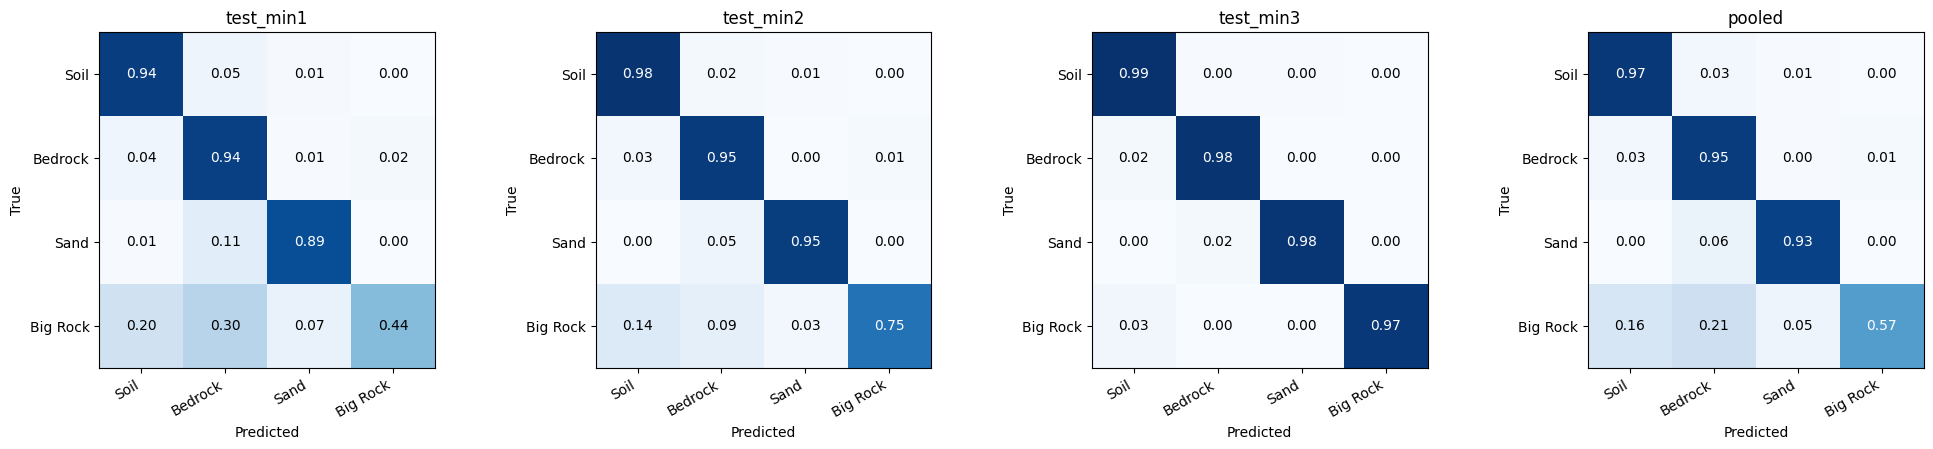

In [10]:
# E10: confusion matrices of the final ensemble (4.1 + 4.2, no bias)
import matplotlib.pyplot as plt
from src.utils.visualization import plot_confusion_matrix

zero = BIASES.index(0.0)
final = conf["ensemble 4.1+4.2"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (split, c) in zip(axes, list(final.items()) + [("pooled", sum(final.values()))]):
    plot_confusion_matrix(c[:, zero].sum(axis=0), ax, title=split)
plt.tight_layout()
plt.savefig(OUT_DIR / "confusion_matrices_ensemble.png", dpi=150, bbox_inches="tight")
plt.show()